<a href="https://colab.research.google.com/github/dia-rodriguez/ising-model-metropolis/blob/main/IsingModel_metropolis_algorithm_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EQUATIONS TO SIMULATE


### **1. Hamiltonian and Free Energy**
$$H = -J \sum_j S_j S_{j+1} - \mu_0 B \sum_j S_j$$
$$F = -k_B T \ln Z$$



### **2. Partition Function**
$$Z = \text{Tr} \exp \left[ +\beta J \sum_j S_j S_{j+1} + \mu_0 B \sum_j S_j \right] \quad ; \quad \mu_0 B(t) = \mu_0 B \xi(t)$$



### **3. Entropy Derivation ($S$)**
$$\begin{align*} S &= -\frac{\partial F}{\partial T} \\   &= +\frac{\partial}{\partial T} (k_B T \ln Z) \\   &= k_B \ln Z + \left( \frac{\partial}{\partial T} \ln Z \right) k_B T \\   &= k_B \ln Z + k_B T \left( \frac{\partial \beta}{\partial T} \frac{\partial}{\partial \beta} \ln Z \right) \\   &= k_B \ln Z + k_B T \left( -\frac{1}{k_B T^2} \right) \left( \frac{1}{Z} \text{Tr} \left[ H e^{-\beta H} \right] \right) \end{align*}$$

**Final Entropy:**
$$\boxed{ S = \frac{\langle H \rangle - F}{T} }$$



### **4. Specific Heat ($C_V$)**
$$C_V = T \left( \frac{\partial S}{\partial T} \right) = \boxed{ \frac{\langle H^2 \rangle - \langle H \rangle^2}{k_B T^2} }$$



### **5. Magnetization ($M$)**
$$\boxed{ M = \left\langle \sum_j S_j \right\rangle } = \frac{1}{\beta} \frac{\partial}{\partial (\mu_0 B)} \ln Z = \text{Tr} \left[ \left( \sum_j S_j \right) e^{-\beta H} \right]$$



### **6. Magnetic Susceptibility ($\chi_B$)**
$$
\begin{aligned}
\chi_B &= \frac{\partial M}{\partial (\mu_0 B)} \\
       &= \beta \left[ \langle M^2 \rangle - \langle M \rangle^2 \right]
\end{aligned}
$$

**Final Susceptibility:**
$$
\boxed{ \chi_B = \beta \left[ \left\langle \left( \sum_j S_j \right)^2 \right\rangle - \left\langle \left( \sum_j S_j \right) \right\rangle^2 \right] }
$$

# IMPORTS


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

# ALGORITHM

In [ ]:
@njit
def metropolis_algorithm(lattice, T, L, J):
  """Perform one metropolis step: propose and accept/reject spin flips."""
  for _ in range(L*L):
    i = np.random.randint(0,L)
    j = np.random.randint(0,L)

    S = lattice[i, j]
    neighbors = (lattice[(i+1) % L,j] + lattice[i, (j+1) % L] + lattice[(i-1) % L,j] + lattice[i, (j-1) % L])

    dE = 2 * J * S * neighbors # Energy change if flipped

    #Metropolis condition: flip with probability exp(-dE / T)
    if dE < 0 or np.random.rand() < np.exp(-dE / T):
      lattice[i, j] *= -1 # Flip the spin


# COMPUTATIONS

In [ ]:
@njit
def calculate_energy(lattice, L, J):
  energy = 0
  for i in range(L): #row
    for j in range(L): #column
      S = lattice[i, j]
      neighbors = (lattice[(i+1) % L,j] + lattice[i, (j+1) % L] + lattice[(i-1) % L,j] + lattice[i, (j-1) % L])
      energy += -J * S *  neighbors
  return energy/2 #each pair is counted twice


In [ ]:
@njit
def calculate_free_energy(E_arr, T):
  """note: Z is just sum of -Energy/kBT, k_B = 1"""
  max_E = np.max(-E_arr/T) #this prevents any crashes
  Z = np.sum(np.exp((-E_arr/T) - max_E))
  k_B = 1
  ln_Z = np.log(Z) + max_E
  F = -k_B*T*ln_Z
  return F

In [ ]:
@njit
def calculate_entropy(E_arr, F, T):
  """note: E_arr is basically our H what need now is use .mean() to get <H>"""
  H_mean = E_arr.mean()
  S = (H_mean - F) / T
  return S

In [ ]:
@njit
def calculate_heat_capacity(E_arr,T):
  """note: what i could do is to compute the averages manually like this (C_v = <H^2> - <H>^2 / k_B * T^2):
k_B
avg_of_squares = (E_arr**2).mean()
square_of_avgs = E_arr.mean()**2
C_v = (avg_of_squares - square_of_avgs) / k_B * T**2

but we take advantage of numpy and use var() instead since the output would be identical
"""
  k_B = 1
  C_v = (E_arr.var() / T**2)
  return C_v

In [ ]:
@njit
def calculate_magnetization(lattice):
  """ note: magnetization (M) is just the sum of the spins in our lattice"""
  M_arr = np.mean(lattice)
  return M_arr

In [ ]:
@njit
def calculate_magnetic_susceptibility(lattice, M_arr, T):
  """ note: we can do .var() again similar to heat capacity instead doing this <M^2> - <M>^2. beta = 1/k_B*T"""
  k_B = 1
  beta = 1 / (k_B * T)
  m_variance = np.var(M_arr)
  chi = beta * lattice.size * m_variance
  return chi

In [ ]:
@njit
def collect_simulation_data(lattice, steps, T, L, J, burn_in):
  # Burn-in part: basically you dont record your early part of the simulation it shakes off some of the randomness to make it stable
  for _ in range(burn_in):
    metropolis_algorithm(lattice, T, L, J)

  # Pre-allocate arrays instead of using Python lists and then converting
  energies = np.empty(steps, dtype=np.float64) # Assuming energy is float
  magnetization = np.empty(steps, dtype=np.float64) # Assuming magnetization is float

  for i in range(steps):
    metropolis_algorithm(lattice, T, L, J)

    #measure and record energy
    energy = calculate_energy(lattice, L, J)
    energies[i] = energy

    #measure and record magnetization
    current_m = calculate_magnetization(lattice)
    magnetization[i] = current_m

  return energies, magnetization


  #update on this function, i added a "burn-in" basically loops on a loop (i forgot to implement)

# SIMULATION LOOP

In [ ]:
@njit
def run_simulation(T_range_param, L, J, steps, burn_in):
  #check the length of temperature array
  num_temperatures = len(T_range_param)

  # set our values into an empty lists/array (using numpy this time)
  F_values = np.empty(num_temperatures, dtype=np.float64)
  S_values = np.empty(num_temperatures, dtype=np.float64)
  C_v_values = np.empty(num_temperatures, dtype=np.float64)
  M_values = np.empty(num_temperatures, dtype=np.float64)
  chi_values = np.empty(num_temperatures, dtype=np.float64)

  # basically our "game loop" so that our values are in an array so we can graph it
  for i in range(num_temperatures):
    current_T = T_range_param[i] # Get the current temperature from the T_range array

    # generate our lattice grid
    lattice = np.random.choice(np.array([1,-1]), size=(L,L)) # it fills our 50x50 grid with either -1 or 1 randomly

    # our energy and magnetization arrays
    E_arr, M_arr = collect_simulation_data(lattice, steps, current_T, L, J, burn_in)

    # generate our computations directly to index i
    F_values[i] = calculate_free_energy(E_arr, current_T)
    S_values[i] = calculate_entropy(E_arr, F_values[i], current_T) # Use F_values[i] for free energy
    C_v_values[i] = calculate_heat_capacity(E_arr, current_T)
    M_values[i] = np.abs(M_arr).mean()
    chi_values[i] = calculate_magnetic_susceptibility(lattice, M_arr, current_T)
  return F_values, S_values, C_v_values, M_values, chi_values, lattice, E_arr, M_arr

# update in function: i used np.empty instead of lists, replaced "for T in T_range:" to
# for i in range(num_temperatures):
#   T = T_range[i]

# PARAMETERS

In [ ]:
# okay so this code is designed to be modular so i dont have to worry about anything so that all you need is to adjust the parameter

L = 20 #lattice size
#T = 2.0 #teperature of the system. we dont need this for now since T is now replaced in the for loop for us to graph it
J = 1 #interaction strength (1 is alligmnent, -1 is anti-alignment)
steps = 20000 #number of monte carlo steps
burn_in = 1000 # number of burn-in or thermalization
T_range = np.linspace(1, 4, 20) #temperature range

# Call the function using the exact same names (its easier for me to keep track)
F_values, S_values, C_v_values, M_values, chi_values, lattice, E_arr, M_arr = run_simulation(T_range, L, J, steps, burn_in)

# for sanity check (incase we play around with values try and test these)
# L = 50, J = 1, steps = 10000, burn_in = 1000, T_range = np.linspace(1, 2, 20)



#PLOTTING

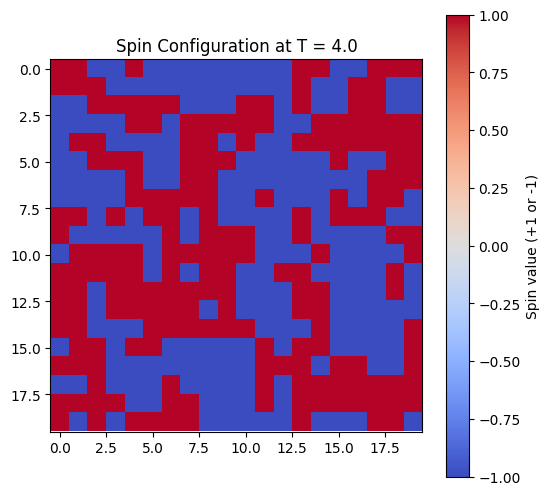

In [ ]:
# plotting our lattice
plt.figure(figsize=(6,6))
plt.imshow(lattice, cmap='coolwarm', interpolation = 'nearest')
plt.title(f'Spin Configuration at T = {T_range[-1]}') # Use the last temperature from T_range
plt.colorbar(label = 'Spin value (+1 or -1)')
plt.show()

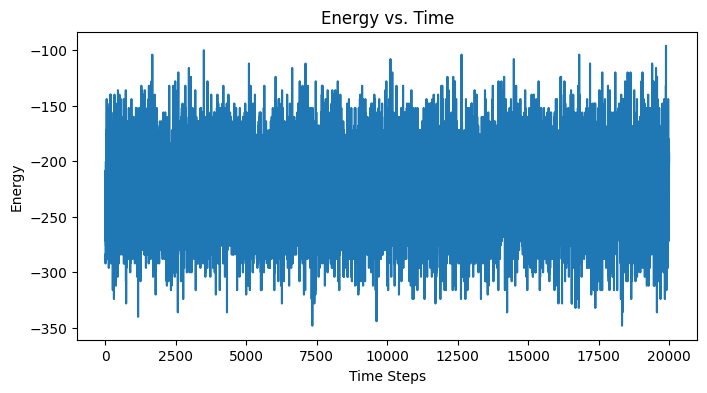

In [ ]:
# plotting our energies
plt.figure(figsize=(8,4))
plt.plot(E_arr, label = 'Energy')
plt.xlabel('Time Steps')
plt.ylabel('Energy')
plt.title('Energy vs. Time')
plt.show()

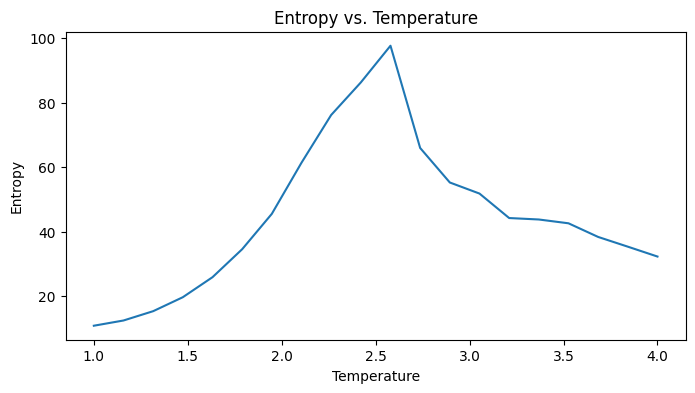

In [ ]:
#Plotting entropy vs temperature range (for now)
plt.figure(figsize=(8,4))
plt.plot(T_range, S_values, label = 'Entropy')
plt.xlabel('Temperature')
plt.ylabel('Entropy')
plt.title('Entropy vs. Temperature')
plt.show()

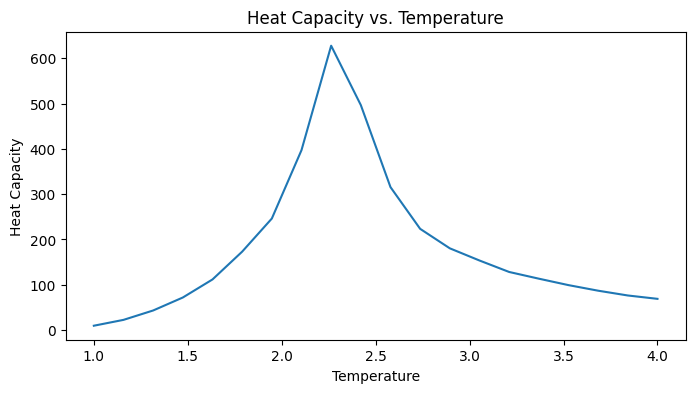

In [ ]:
# Plotting heat capacity vs temperature
plt.figure(figsize=(8,4))
plt.plot(T_range, C_v_values, label = 'Heat Capacity')
plt.xlabel('Temperature')
plt.ylabel('Heat Capacity')
plt.title('Heat Capacity vs. Temperature')
plt.show()

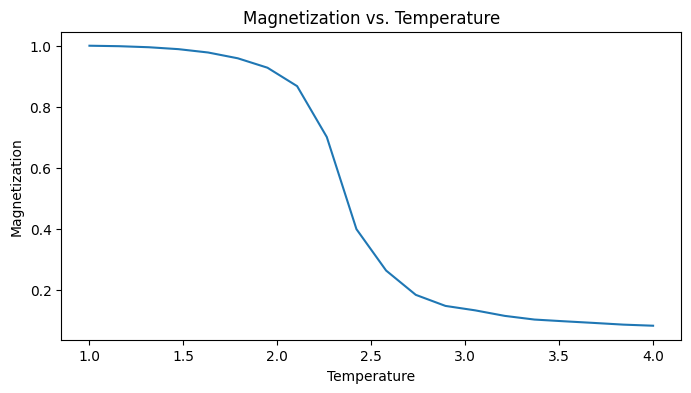

In [ ]:
# Plotting magnetization vs temperature
plt.figure(figsize=(8,4))
plt.plot(T_range, M_values, label = 'Magnetization')
plt.xlabel('Temperature')
plt.ylabel('Magnetization')
plt.title('Magnetization vs. Temperature')
plt.show()

Text(0.5, 1.0, 'Magnetic Susceptibility vs. Temperature')

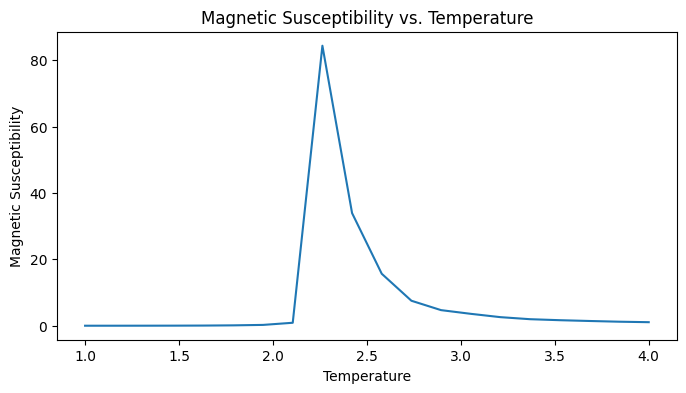

In [ ]:
# Plotting chi (magnetic susceptibility) vs temperature
plt.figure(figsize=(8,4))
plt.plot(T_range, chi_values, label = 'Magnetic Susceptibility')
plt.xlabel('Temperature')
plt.ylabel('Magnetic Susceptibility')
plt.title('Magnetic Susceptibility vs. Temperature')